# HSC statistics: training-only surrogate pretraining and multifidelity NPE

This new notebook leaves `SBI_test_v4.ipynb` unchanged. Use the **sbi** Conda environment.

The low-fidelity data are **statistical augmentation**, not new physical simulations.
A Gaussian copula is fitted jointly to all five statistics, using only 35 training
cosmologies. Empirical marginals are conditional on each training cosmology. We
generate 500 examples per training node (17,500 total). Scalar ranges are preserved,
but Gaussian-copula sampling need not preserve exact multibin histogram/MF constraints.
No interpolation to new cosmologies is claimed.

Seven entire cosmologies are used for validation and eight for the final test.
Preprocessing and the surrogate never fit validation or test summaries. Both
training phases select checkpoints using the same high-fidelity validation split.

All five statistics use the complete Gabriela collection with shared realization indices
0..49. The original parameter mapping is retained; the arrays do not embed realization IDs.
This replaces the original mixed DI/Gabriela selection because DI outputs are incomplete. C_ell retains the original 300–2000 cut and first three tomographic bins;
other statistics retain four bins. This workflow preserves the supplied Gabriela statistics and does not remeasure maps.

**Scientific scope:** the target order is `(S8, Omega_m)`. The source design also varies
`h0` and gravity parameters. These fitted conditional densities reflect the finite
design; controlled nuisance marginalization and a continuous cosmological prior have
not been established. Held-out coverage below is a diagnostic, not prior-predictive SBC.


In [1]:
import sys
print(sys.executable)
assert '/envs/sbi/' in sys.executable, 'Select the sbi Conda Python environment.'
REBUILD_DATA = False
RETRAIN = False
SEEDS = (42,)  # e.g. (42, 43, 44) for an equal-weight posterior ensemble


/home/hedi/data/miniforge3/envs/sbi/bin/python


## 1. Build and audit the low-fidelity set first

The following definitions are included directly so this notebook is self-contained.
`splits.json`, the complete source manifest, surrogate fit, raw HF arrays, and LF
training arrays are saved under `SBI/multifidelity_surrogate_v1`.


In [2]:
from pathlib import Path
import copy
import hashlib
import json
import time
import numpy as np
from scipy.stats import rankdata, norm
from sklearn.covariance import LedoitWolf

ROOT = Path('/home/hedi/HSCNG')
OUT = ROOT / 'SBI/multifidelity_surrogate_v1'
KEYS = ['C_ell', 'peaks', 'minima', 'pdf', 'MFs']
SEED = 42
SOURCE = Path('/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied')

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2))

def prepare(n_per_cosmology=500):
    """Build LF first. No validation/test summaries enter any fitted transform."""
    from astropy.io import fits
    import pymaster as nmt
    OUT.mkdir(exist_ok=True)
    original = ROOT / 'SBI/SBI_test_v4.ipynb'
    original_hash = hashlib.sha256(original.read_bytes()).hexdigest()
    pars = np.loadtxt(ROOT / 'data/cosmo_params.txt', skiprows=1)
    assert len(pars) == 50 and np.array_equal(pars[:, 0], np.arange(50))
    theta = pars[:, [3, 1]]  # S8, Omega_m, matching original notebook
    rng = np.random.default_rng(SEED)
    ids = rng.permutation(len(pars))
    split = dict(train=sorted(ids[:35].tolist()), validation=sorted(ids[35:42].tolist()),
                 test=sorted(ids[42:].tolist()))
    assert len(set(sum(split.values(), []))) == 50
    save_json(OUT / 'splits.json', split)
    fields = ['XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
    counts = []
    for field, n in zip(fields, [8, 25, 23, 7, 26, 13]):
        total = np.zeros(4)
        for i in range(n):
            with fits.open(ROOT / f'data/real/hscy3_shape_chopped_{field}_{i}.fits', memmap=True) as h:
                z = h[1].data['hsc_y3_zbin']
                total += [(z == t).sum() for t in range(1, 5)]
        counts.append(total)
    counts = np.asarray(counts)
    edges = np.unique(np.logspace(np.log10(80), np.log10(6500), 15))
    ell = nmt.NmtBinFlat(edges[:-1], edges[1:]).get_effective_ells()
    ell_mask = (ell >= 300) & (ell <= 2000)
    sources = []
    def aggregate(folder, statistic, tomos, sum_fields=False):
        result = []
        for c in range(50):
            per_tomo = []
            for t in tomos:
                arrays = []
                for field in fields:
                    f = SOURCE / folder / f'model{c}_{statistic}_z{t}_{field}.npy'
                    a = np.load(f, allow_pickle=False)
                    assert a.shape == (50, 14 if statistic == 'Clee' else 19), (str(f), a.shape)
                    assert np.isfinite(a).all(), str(f)
                    sources.append(dict(path=str(f), size=f.stat().st_size, mtime_ns=f.stat().st_mtime_ns))
                    arrays.append(a)
                a = np.sum(arrays, axis=0) if sum_fields else np.average(arrays, axis=0, weights=counts[:, t-1])
                if statistic == 'Clee':
                    a = a[:, ell_mask]
                per_tomo.append(a)
            result.append(np.concatenate(per_tomo, axis=-1))
        print('Loaded', statistic, flush=True)
        return np.asarray(result)
    # Complete Gabriela collection for every branch. The index-to-parameter mapping
    # follows v4; .npy arrays lack embedded realization IDs (audit before science use).
    raw = {'C_ell': aggregate('power_spectrum', 'Clee', [1, 2, 3]),
           'peaks': aggregate('peaks', 'Peaks', [1, 2, 3, 4], True),
           'minima': aggregate('minima', 'Minima', [1, 2, 3, 4], True),
           'pdf': aggregate('pdf', 'pdf', [1, 2, 3, 4]),
           'MFs': np.concatenate([aggregate('MFs', s, [1, 2, 3, 4]) for s in ['V0','V1','V2']], axis=-1)}
    dims = {k: raw[k].shape[-1] for k in KEYS}
    x = np.concatenate([raw[k] for k in KEYS], axis=-1)
    train = x[split['train']]
    mean = train.mean(axis=(0, 1))
    scale = train.std(axis=(0, 1))
    scale[scale == 0] = 1.
    normalized = (x - mean) / scale
    np.savez_compressed(OUT/'high_fidelity.npz', x=x.astype('float32'),
                        theta=theta.astype('float32'), parameters_full=pars,
                        x_mean=mean, x_scale=scale, cosmology_id=np.arange(50),
                        realization_id=np.arange(50))
    # Rank within each cosmology; fit one pooled, regularized cross-statistic copula.
    # Conditional empirical marginals prevent negative histogram counts and respect
    # scalar support. A Gaussian copula does NOT enforce all multibin constraints.
    ranks = rankdata(train, axis=1, method='average')
    gaussian = norm.ppf((ranks - .5) / train.shape[1])
    gaussian -= gaussian.mean(axis=1, keepdims=True)
    covariance = LedoitWolf().fit(gaussian.reshape(-1, x.shape[-1])).covariance_
    sd = np.sqrt(np.diag(covariance))
    correlation = covariance / np.outer(sd, sd)
    chol = np.linalg.cholesky(correlation + 1e-8*np.eye(len(sd)))
    quantiles = np.sort(train, axis=1)
    np.savez_compressed(OUT/'surrogate_fit.npz', correlation=correlation,
                        conditional_quantiles=quantiles, train_cosmology_id=split['train'])
    generated = []
    for q in quantiles:
        u = norm.cdf(rng.standard_normal((n_per_cosmology, x.shape[-1])) @ chol.T)
        pos = u * (q.shape[0]-1)
        lo = np.floor(pos).astype(int)
        hi = np.minimum(lo+1, q.shape[0]-1)
        frac = pos-lo
        j = np.arange(q.shape[1])[None, :]
        generated.append(q[lo,j]*(1-frac) + q[hi,j]*frac)
    lf_raw = np.concatenate(generated)
    lf_ids = np.repeat(split['train'], n_per_cosmology)
    assert not set(lf_ids) & set(split['validation'] + split['test'])
    assert np.isfinite(lf_raw).all()
    np.savez_compressed(OUT/'low_fidelity_train.npz',
                        x=lf_raw.astype('float32'),
                        theta=theta[lf_ids].astype('float32'), cosmology_id=lf_ids,
                        synthetic_realization_id=np.tile(np.arange(n_per_cosmology),35))
    # Diagnostics only use training data; test remains unused until final evaluation.
    lf_group = lf_raw.reshape(35, n_per_cosmology, -1)
    mean_error = np.abs(lf_group.mean(1)-train.mean(1))/scale
    report = dict(method='training-only conditional empirical-marginal Gaussian copula',
                  n_lf=len(lf_raw), n_hf_train=1750, n_hf_validation=350, n_hf_test=400,
                  n_per_cosmology=n_per_cosmology, branch_dims=dims, seed=SEED,
                  mean_absolute_shift_in_training_std=float(mean_error.mean()),
                  split=split, target_order=['S8','Omega_m'], original_sha256=original_hash,
                  source=str(SOURCE),
                  realization_order='shared array indices 0..49 from Gabriela collection; original notebook mapping retained',
                  limitations=[
                      'Synthetic augmentation at existing training nodes, not independent simulations or new cosmologies.',
                      'Cross-statistic realization identity and parameter mapping follow v4 and require source provenance verification.',
                      'Pooled Gaussian copula approximates dependence; scalar support is preserved, joint histogram/MF constraints need not be.',
                      'All 50 light cones per node are grouped; cones are not assumed independent cosmologies.',
                      'Two-parameter conditional density reflects finite simulation design, not a demonstrated continuous-prior posterior.',
                      'h0 and gravity columns vary; no controlled nuisance-prior marginalization is established.'])
    save_json(OUT/'data_report.json', report)
    save_json(OUT/'source_manifest.json', sources)
    current_hash = hashlib.sha256(original.read_bytes()).hexdigest()
    save_json(OUT/'original_notebook_audit.json', dict(build_start_sha256=original_hash, current_sha256=current_hash, changed_during_work=current_hash != original_hash, workflow_access='read-only'))
    print(json.dumps(report, indent=2), flush=True)
    return report


In [3]:
if REBUILD_DATA or not (OUT/'data_report.json').exists():
    data_report = prepare(n_per_cosmology=500)
else:
    data_report = json.loads((OUT/'data_report.json').read_text())
print('Original notebook checksum matches build start:', hashlib.sha256((ROOT/'SBI/SBI_test_v4.ipynb').read_bytes()).hexdigest() == data_report['original_sha256'])
print('This workflow only reads the original notebook; concurrent external edits are preserved.')
print(json.dumps(data_report, indent=2))


Original notebook checksum matches build start: False
This workflow only reads the original notebook; concurrent external edits are preserved.
{
  "method": "training-only conditional empirical-marginal Gaussian copula",
  "n_lf": 17500,
  "n_hf_train": 1750,
  "n_hf_validation": 350,
  "n_hf_test": 400,
  "n_per_cosmology": 500,
  "branch_dims": {
    "C_ell": 18,
    "peaks": 76,
    "minima": 76,
    "pdf": 76,
    "MFs": 228
  },
  "seed": 42,
  "mean_absolute_shift_in_training_std": 0.0232257267810278,
  "split": {
    "train": [
      3,
      4,
      5,
      7,
      9,
      10,
      15,
      16,
      17,
      18,
      20,
      21,
      23,
      24,
      25,
      26,
      27,
      28,
      29,
      30,
      31,
      32,
      34,
      37,
      38,
      39,
      40,
      41,
      42,
      43,
      44,
      45,
      46,
      47,
      49
    ],
    "validation": [
      0,
      6,
      11,
      12,
      19,
      22,
      35
    ],
    "test": [


## 2. Five small encoders and a joint embedding

Each branch maps its input through 64 → 32 → 8 units (MFs: 128 → 32 → 8).
The concatenated 40 values pass through 32 → 8 units, conditioning an sbi
five-component MDN. All encoders, the joint embedding, and the MDN are optimized
together with posterior negative log-likelihood; there is no two-number MSE bottleneck.

We use sbi's density-estimator builder with an explicit training loop to keep the
cosmology-level split exact. See [sbi embedding networks](https://sbi-dev.github.io/sbi/dev/tutorials/04_embedding_networks/).
Pretraining uses learning rate 2e-4, then all weights are fine-tuned at 2e-5.
Input and parameter normalization remain fixed across the two phases.


In [4]:

def load_data():
    import torch
    report = json.loads((OUT/'data_report.json').read_text())
    h = np.load(OUT/'high_fidelity.npz')
    l = np.load(OUT/'low_fidelity_train.npz')
    mean, scale = h['x_mean'], h['x_scale']
    def tensors(x, y):
        return torch.tensor((x-mean)/scale, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)
    sets = {}
    for name, ids in report['split'].items():
        sets[name] = tensors(h['x'][ids].reshape(-1,len(mean)), np.repeat(h['theta'][ids],50,axis=0))
    sets['low'] = tensors(l['x'], l['theta'])
    return sets, report

def make_model(dims, x, theta, seed):
    import torch
    from torch import nn
    from sbi.neural_nets import posterior_nn
    torch.manual_seed(seed)
    class JointEmbedding(nn.Module):
        def __init__(self):
            super().__init__()
            self.widths = [dims[k] for k in KEYS]
            self.branches = nn.ModuleDict({k: nn.Sequential(
                nn.Linear(dims[k],128 if k=='MFs' else 64), nn.GELU(),
                nn.Linear(128 if k=='MFs' else 64,32), nn.GELU(),nn.Linear(32,8)) for k in KEYS})
            self.joint = nn.Sequential(nn.Linear(40,32),nn.GELU(),nn.Linear(32,8))
        def forward(self, x):
            parts = torch.split(x,self.widths,dim=-1)
            return self.joint(torch.cat([self.branches[k](v) for k,v in zip(KEYS,parts)],dim=-1))
    embedding = JointEmbedding()
    # sbi builds the estimator; explicit training below preserves group splits.
    build = posterior_nn(model='mdn', hidden_features=32, num_components=5,
                         embedding_net=embedding, z_score_x='none', z_score_theta='independent')
    return build(theta, x)

def train_stage(model, data, validation, lr, epochs, patience, seed, stage):
    import torch
    from torch.utils.data import DataLoader, TensorDataset
    torch.manual_seed(seed)
    # All parameters remain trainable in both phases. Fresh optimizer at lower LR.
    for p in model.parameters(): p.requires_grad_(True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(*data),batch_size=128,shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    best, state, bad, history = float('inf'), None, 0, []
    initial = {n:p.detach().clone() for n,p in model.named_parameters()}
    for epoch in range(epochs):
        model.train()
        total = 0.
        for xb, tb in loader:
            optimizer.zero_grad()
            loss = model.loss(tb, condition=xb).mean()
            if not torch.isfinite(loss): raise RuntimeError('Non-finite training loss')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),5.)
            optimizer.step()
            total += float(loss.detach())*len(xb)
        model.eval()
        with torch.no_grad():
            val = float(model.loss(validation[1],condition=validation[0]).mean())
        history.append(dict(epoch=epoch+1,train=total/len(data[0]),validation=val))
        if val < best-1e-5:
            best, state, bad = val, copy.deepcopy(model.state_dict()), 0
        else: bad += 1
        if epoch%10 == 0: print(stage,epoch+1,history[-1],flush=True)
        if bad >= patience: break
    assert state is not None
    model.load_state_dict(state)
    changed = {n:bool(not torch.equal(p.detach(),initial[n])) for n,p in model.named_parameters()}
    # Verify each statistic branch, joint net, and density head participated.
    for key in KEYS:
        assert any(v for n,v in changed.items() if 'branches.'+key+'.' in n), key
    assert any(v for n,v in changed.items() if '.joint.' in n)
    return dict(stage=stage,lr=lr,best_validation_nll=best,history=history,changed_parameters=changed)

def run_training(seeds=(42,), pretrain_epochs=80, finetune_epochs=120, baseline_epochs=120):
    import torch, sbi
    torch.set_num_threads(2)
    sets, report = load_data()
    models, results = [], []
    for seed in seeds:
        model = make_model(report['branch_dims'],*sets['train'],seed)
        pre = train_stage(model,sets['low'],sets['validation'],2e-4,pretrain_epochs,15,seed,'low')
        torch.save(model.state_dict(),OUT/f'pretrained_seed{seed}.pt')
        fine = train_stage(model,sets['train'],sets['validation'],2e-5,finetune_epochs,25,seed+1,'high')
        torch.save(model.state_dict(),OUT/f'finetuned_seed{seed}.pt')
        models.append(model)
        results.append(dict(seed=seed,pretrain=pre,finetune=fine))
    baseline = make_model(report['branch_dims'],*sets['train'],seeds[0])
    base = train_stage(baseline,sets['train'],sets['validation'],2e-4,baseline_epochs,25,seeds[0],'HF-only')
    torch.save(baseline.state_dict(),OUT/'baseline.pt')
    result = dict(sbi_version=sbi.__version__,torch_version=torch.__version__,
                  members=results,baseline=base,ensemble='equal-weight density mixture',
                  device='cpu',num_threads=2)
    save_json(OUT/'training_report.json',result)
    return models, baseline, result

def restore_models(seeds=(42,)):
    import torch
    sets, report = load_data()
    models = []
    for seed in seeds:
        m = make_model(report['branch_dims'],*sets['train'],seed)
        m.load_state_dict(torch.load(OUT/f'finetuned_seed{seed}.pt',weights_only=True))
        m.eval(); models.append(m)
    baseline = make_model(report['branch_dims'],*sets['train'],seeds[0])
    baseline.load_state_dict(torch.load(OUT/'baseline.pt',weights_only=True))
    baseline.eval()
    return models, baseline


In [5]:
import torch
torch.set_num_threads(2)
if RETRAIN or not all((OUT/f'finetuned_seed{s}.pt').exists() for s in SEEDS):
    models, baseline, training_report = run_training(seeds=SEEDS)
else:
    models, baseline = restore_models(seeds=SEEDS)
    training_report = json.loads((OUT/'training_report.json').read_text())
for member in training_report['members']:
    print('Seed', member['seed'], 'pretrain NLL', member['pretrain']['best_validation_nll'],
          'fine-tune NLL', member['finetune']['best_validation_nll'])
print('HF-only validation NLL', training_report['baseline']['best_validation_nll'])


Seed 42 pretrain NLL -2.7208340167999268 fine-tune NLL -2.8120555877685547
HF-only validation NLL -2.982104539871216


## 3. Held-out evaluation and optional ensemble

The test set is accessed after model selection. Ensembles mix densities/samples,
not model weights or parameter means. The MDN is unbounded; no post-hoc prior
truncation is silently imposed. Examine coverage and the HF-only baseline before
using this exploratory model for observations. Eight test cosmologies provide
limited evidence, and cones within a cosmology may be correlated.


In [6]:

def ensemble_sample(models, x, n=2000, seed=123):
    """Equal-weight mixture: select a member per draw, never average parameters."""
    import torch
    torch.manual_seed(seed)
    assignments = torch.randint(len(models),(n,))
    draws = torch.empty(n,len(x),2)
    with torch.no_grad():
        for i,m in enumerate(models):
            mask = assignments==i
            if mask.any(): draws[mask] = m.sample((int(mask.sum()),),condition=x)
    return draws

def evaluate(models, baseline, n_samples=1000):
    import torch
    sets, report = load_data()
    x,y = sets['test']
    result = {}
    for name, members in [('multifidelity',models),('HF_only', [baseline])]:
        for m in members: m.eval()
        with torch.no_grad():
            # loss is per observation; a mixture averages densities, not NLLs.
            ll = torch.stack([-m.loss(y,condition=x) for m in members])
            nll = -(torch.logsumexp(ll,dim=0)-np.log(len(members)))
            draws = ensemble_sample(members,x,n_samples)
            q = torch.quantile(draws,torch.tensor([.025,.16,.5,.84,.975]),dim=0)
        cover68 = ((y>=q[1])&(y<=q[3])).float()
        cover95 = ((y>=q[0])&(y<=q[4])).float()
        result[name] = dict(test_nll=float(nll.mean()),
            coverage68=cover68.mean(0).tolist(),coverage95=cover95.mean(0).tolist(),
            median_bias=(q[2]-y).mean(0).tolist(),
            per_cosmology_nll=nll.reshape(8,50).mean(1).tolist(),
            per_cosmology_coverage68=cover68.reshape(8,50,2).mean(1).tolist())
        np.savez_compressed(OUT/f'{name}_test_quantiles.npz',quantiles=q.numpy(),truth=y.numpy())
    result['note'] = 'Finite held-out design diagnostic; not prior-predictive SBC. Cones within a cosmology are correlated. No prior truncation is applied.'
    result['test_cosmology_ids'] = report['split']['test']
    save_json(OUT/'evaluation.json',result)
    current_hash = hashlib.sha256((ROOT/'SBI/SBI_test_v4.ipynb').read_bytes()).hexdigest()
    save_json(OUT/'original_notebook_audit.json', dict(build_start_sha256=report['original_sha256'], current_sha256=current_hash, changed_during_work=current_hash != report['original_sha256'], workflow_access='read-only'))
    print(json.dumps(result,indent=2),flush=True)
    return result


In [7]:
if RETRAIN or not (OUT/'evaluation.json').exists():
    evaluation = evaluate(models, baseline, n_samples=1000)
else:
    evaluation = json.loads((OUT/'evaluation.json').read_text())
    print(json.dumps(evaluation, indent=2))


{
  "multifidelity": {
    "test_nll": -2.4128472805023193,
    "coverage68": [
      0.5699999928474426,
      0.512499988079071
    ],
    "coverage95": [
      0.8849999904632568,
      0.824999988079071
    ],
    "median_bias": [
      0.001955294981598854,
      0.006815609987825155
    ],
    "per_cosmology_nll": [
      -0.4863593578338623,
      -3.1115405559539795,
      -2.1510772705078125,
      -2.296938419342041,
      -2.9049439430236816,
      -2.823944091796875,
      -2.6507909297943115,
      -2.8771843910217285
    ],
    "per_cosmology_coverage68": [
      [
        0.699999988079071,
        0.0
      ],
      [
        0.7400000095367432,
        0.20000000298023224
      ],
      [
        0.6600000262260437,
        0.6600000262260437
      ],
      [
        0.6000000238418579,
        0.6800000071525574
      ],
      [
        0.41999998688697815,
        0.46000000834465027
      ],
      [
        0.3799999952316284,
        0.6399999856948853
      ],
   

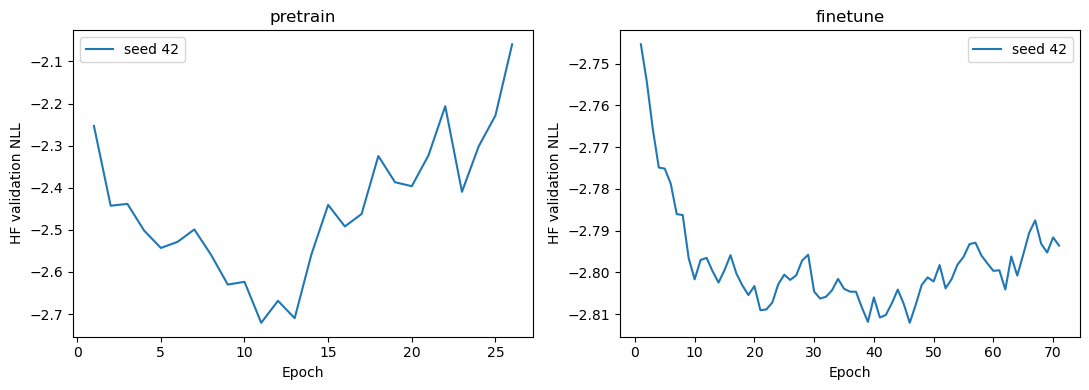

In [8]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for member in training_report['members']:
    for ax, stage in zip(axes, ['pretrain','finetune']):
        h = member[stage]['history']
        ax.plot([v['epoch'] for v in h], [v['validation'] for v in h], label=f"seed {member['seed']}")
        ax.set(xlabel='Epoch', ylabel='HF validation NLL', title=stage)
        ax.legend()
plt.tight_layout()
plt.show()


## Reuse and remaining scientific checks

For new observations, construct the same ordered statistics, subtract `x_mean` and
divide by `x_scale` from `high_fidelity.npz`, then use `ensemble_sample(models, x)`.
Do not refit normalization to observations. Preserve the saved branch dimensions.

Before a scientific result: verify source arrays against their map/realization IDs,
check the MF mask conventions, specify the intended cosmological/nuisance prior,
and validate across more held-out cosmology splits. The original index convention is retained, but individual .npy files do not embed realization IDs. More synthetic
rows cannot resolve missing physical information or establish calibration.
